# FDM expansion for Diffusive Equations

In [4]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
import sympy as sp
import numpy as np
import re as regex
from sympy.tensor.indexed import Indexed
from IPython.display import display, Math, Latex
%run ~/Desktop/Bazarin-R.L.M.-AcademicDocumentation/docs/source/modules/eq_funcs.ipynb

us = sp.symbols('u_{x}^{t}')
omega = sp.symbols(r'\omega')
omg1=1-omega
cs = sp.symbols('c_s')

In [5]:
def make_shift_symbols(prefix=r'T_{\Delta_{x}}', order=9, var='c', start=0):
    names = [f'{prefix}^{{{var}_{{{i}}}}}' for i in range(start, start + order)]
    return sp.symbols(names)
Txc = make_shift_symbols(order=18, var='c')   # list of SymPy symbols
# Txc

In [6]:
def auto_collect(expr, ul):
    symbols = set(ul.values()) & expr.free_symbols
    symbols = sorted(symbols, key=sp.default_sort_key)
    return sp.collect(expr, symbols)

In [7]:
def wheigt_symbols(prefix=r'w', order=9, start=0):
    names = [f'{prefix}_{{{i}}}' for i in range(start, start + order)]
    return sp.symbols(names)
w = wheigt_symbols(order=18)   # list of SymPy symbols
# w[0]

 ## Two-Dimensional Cases: $D2Q9$ Lattices

In [8]:
import sympy as sp
#------------------Shift-Function-----------------------------------
def apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-2):
    if len(cx) != len(cy) or len(cx) > len(Txc):
        raise ValueError("Incompatible lattice velocity arrays")
    velocities = [(int(x), int(y)) for x, y in zip(cx, cy)]
    operators = Txc[:len(velocities)]
    if expr.has(*Txc[len(velocities):]):
        raise ValueError("Some shift operators have undefined velocities")
    result = []
    # Expand into individual additive terms
    for term in sp.Add.make_args(sp.expand(expr)):
        powers = term.as_powers_dict()
        counts = [powers.get(op, 0) for op in operators]# Number of occurrences of each shift operator
        operator_factor = sp.prod(op**n for op, n in zip(operators, counts) ) # Extract operator product
        other = term / operator_factor
        # ------Case 1: Shift operators acting on us-----------
        if powers.get(us, 0) == 1:

            dx = -sum(int(n) * vx for n, (vx, vy) in zip(counts, velocities))
            dy = -sum(int(n) * vy for n, (vx, vy) in zip(counts, velocities) )

            # Build dictionary key
            key = f"ut{time}"
            if dx:
                key += f"dx{dx:+d}"
            if dy:
                key += f"dy{dy:+d}"
            # Generate missing symbols automatically
            if key not in ul:
                te = f"t{time:+d}" if time else "t"
                xp = f"x{dx:+d}" if dx else "x"
                yp = f"y{dy:+d}" if dy else "y"
                ul[key] = sp.Symbol(fr"u^{{{te}}}_{{{xp},{yp}}}")
            result.append((other / us) * ul[key])
        # ---Case 2: Simplify shift operators not acting on us---
        else:
            reduced = [int(n) for n in counts]
            for i, (vx, vy) in enumerate(velocities):
                # Zero-velocity operator is identity
                if vx == 0 and vy == 0:
                    reduced[i] = 0
                    continue
                # Cancel opposite shifts
                for j in range(i + 1, len(velocities)):
                    if velocities[j] == (-vx, -vy):
                        m = min(reduced[i], reduced[j])
                        reduced[i] -= m
                        reduced[j] -= m
            remaining = sp.prod(op**n for op, n in zip(operators, reduced))
            result.append(other * remaining)
    return sp.Add(*result)

In [9]:
import sympy as sp
ul = {}
past_steps = [1, 2, 3, 4, 5, 6]
space_offsets = [1, 2, 3, 4, 5, 6]
# Time mapping
time_map = {"+1": "t+1","0": "t",**{f"-{k}": f"t-{k}" for k in past_steps},}
# Non-shifted symbols
for tk, te in time_map.items():
    ul[f"ut{tk}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y}}')
# Shifted symbols (skip future time "+1")
for tk, te in time_map.items():
    if tk == "+1":
        continue
    for ssign in ("+", "-"):
        for d in space_offsets:
            # Shift in x
            ul[f"ut{tk}dx{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x{ssign}{d},y}}')
            # Shift in y
            ul[f"ut{tk}dy{ssign}{d}"] = sp.Symbol(fr'u^{{{te}}}_{{x,y{ssign}{d}}}')
    # Simultaneous shifts in x and y
    for sx in ("+", "-"):
        for sy in ("+", "-"):
            for dx in space_offsets:
                for dy in space_offsets:
                    ul[f"ut{tk}dx{sx}{dx}dy{sy}{dy}"] = sp.Symbol(fr'u^{{{te}}}_{{x{sx}{dx},y{sy}{dy}}}')

In [10]:
import warnings
warnings.filterwarnings("ignore")
from pylab import *
from sympy import *
import numpy as np
q=9
cx=np.array([0, 1,-1, 0, 0, 1,-1,-1, 1])
cy=np.array([0, 0, 0, 1,-1, 1, 1,-1,-1])
wis=np.array([w[0],w[1],w[2],w[3],w[4],w[5],w[6],w[7],w[8]])
feq = us*wis

In [11]:
from itertools import combinations
import sympy as sp

OrderT = sp.Matrix([
    sum(
        (-omg1)**(n-1)
        * sp.prod(Txc[i] for i in idx)
        * (omega * sum(feq[i] for i in idx) + (1-omega)*us)
        for idx in combinations(range(q), n)
    )
    for n in range(1, 10)
])

In [12]:
weights = {w[0]: sp.Rational(4, 9), **{w[i]: sp.Rational(1, 9) for i in range(1, 5)}, **{w[i]: sp.Rational(1, 36) for i in range(5, 9)} }
# Automatically process all orders
mt = {}
for i in range(len(OrderT)):
    expr = sp.expand(OrderT[i])
    expr = apply_velocity_shifts(expr, Txc, cx, cy, us, ul, time=-i)
    mt[i] = auto_collect(expr.subs(weights), ul)
    print(f"Order {i}:")
    brokeq2(mt[i], terms_per_line=4)

Order 0:


<IPython.core.display.Math object>

Order 1:


<IPython.core.display.Math object>

Order 2:


...

<IPython.core.display.Math object>

Order 7:


<IPython.core.display.Math object>

Order 8:


<IPython.core.display.Math object>

In [13]:
display(Math(fdm_ordered_brokeq(sp.Eq(ul['ut+1'],mt[0]+mt[1]+mt[2]+mt[3]+mt[4]+mt[5]+mt[6]+mt[7]+mt[8]), terms_per_line=4, symbols=ul)))

<IPython.core.display.Math object>

In [14]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import re

def plot_fdm_stencil(mt, ul, cx, cy, figsize=(7, 7)):
    # ----------------1. Identify Cartesian positions from ul symbols----------------------------------
    pattern = re.compile(r"^ut(?:\+1|0|-\d+)"r"(?:dx([+-]\d+))?"r"(?:dy([+-]\d+))?$")
    # Reverse mapping: SymPy symbol -> dictionary key
    symbol_to_key = {v: k for k, v in ul.items()}
    points_by_order = {}
    for i, expr in mt.items():
        points = set()
        for symbol in expr.free_symbols:
            key = symbol_to_key.get(symbol)
            if key is None:
                continue
            match = pattern.fullmatch(key)
            if match is None:
                continue
            dx = int(match.group(1) or 0)
            dy = int(match.group(2) or 0)
            points.add((dx, dy))
        points_by_order[i] = points
    # --------------------Union of all Cartesian points------------------------------
    all_points = set().union(*points_by_order.values())
    if not all_points:
        raise ValueError("No shifted spatial symbols found.")
    # Original lattice velocities
    base_points = {(-int(x), -int(y)) for x, y in zip(cx, cy)}
    # Only count points actually present in mt
    black_points = all_points & base_points
    red_points = all_points - base_points
    # --------------------Print stencil information------------------------------
    # for i, points in sorted(points_by_order.items()):
    #     print(f"mt[{i}]: {len(points)} Cartesian points")

    # print(f"\nOriginal lattice points: {len(black_points)}")
    # print(f"Additional points:       {len(red_points)}")
    # print(f"Total stencil points:    {len(all_points)}")
    # ---------------------4. Plot-----------------------------
    fig, ax = plt.subplots(figsize=figsize)
    if black_points:
        x, y = zip(*sorted(black_points))
        ax.scatter(x, y, color="black", s=100, zorder=3)
    if red_points:
        x, y = zip(*sorted(red_points))
        ax.scatter(x, y, color="red", s=100, zorder=3)
    xs, ys = zip(*all_points)
    ax.set_xticks(np.arange(min(xs), max(xs) + 1))
    ax.set_yticks(np.arange(min(ys), max(ys) + 1))
    ax.set_xlim(min(xs) - 0.5, max(xs) + 0.5)
    ax.set_ylim(min(ys) - 0.5, max(ys) + 0.5)
    ax.set_aspect("equal")
    ax.grid(True, color="lightgray", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.set_xlabel(r"$\Delta x$")
    ax.set_ylabel(r"$\Delta y$")
    ax.set_title(f"{len(all_points)}-point stencil " f"({len(black_points)} + {len(red_points)})" )
    plt.tight_layout()
    plt.show()
    return all_points, points_by_order

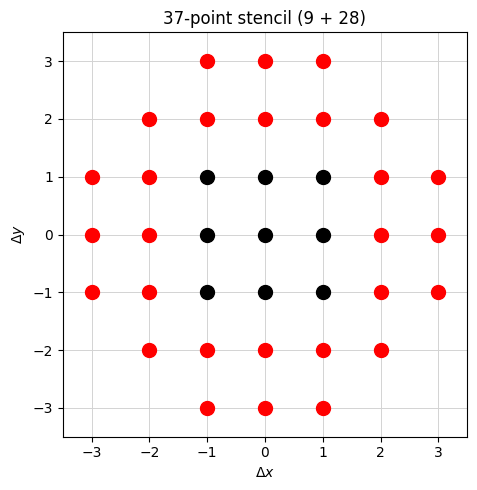

In [76]:
all_points, points_by_order = plot_fdm_stencil(mt, ul, cx, cy, figsize=(5, 5))

### Sympy Expansion

In [15]:
import sympy as sp
# -----------------------------------------------------------------------------
# 1) Symbols (parameters and step sizes)
# -----------------------------------------------------------------------------
dx, dt = sp.symbols('Delta_x Delta_t', positive=True, real=True)
nu = sp.symbols('\\nu')

def d(name, nx=0, nt=0):
    n = nx + nt
    if n == 1:
        num = rf"\partial{{{name}}}"
    else:
        num = rf"\partial^{{{n}}}{{{name}}}"
    den = ""
    if nx:
        den += rf"\partial{{x^{{{nx}}}}}" if nx > 1 else r"\partial{x}"
    if nt:
        den += rf"\partial{{t^{{{nt}}}}}" if nt > 1 else r"\partial{t}"
    return sp.Symbol(rf"\frac{{{num}}}{{{den}}}")
# -------------------1st-Order-Terms----------------------
dut = d(r"u", nt=1); dux   = d(r"u", nx=1)
# -------------------2nd-Order-Terms----------------------
dux2 = d(r"u", nx=2); duxt = d(r"u", nx=1, nt=1); dut2 = d(r"u", nt=2)
# -------------------3rd-Order-Terms----------------------
dux3 = d(r"u", nx=3); dux2t = d(r"u", nx=2, nt=1); duxt2 = d(r"u", nx=1, nt=2); dut3  = d(r"u", nt=3)
# -------------------4th-Order-Terms----------------------
dux4 = d(r"u", nx=4); dux3t = d(r"u", nx=3, nt=1); dux2t2 = d(r"u", nx=2, nt=2); duxt3 = d(r"u", nx=1, nt=3); dut4 = d(r"u", nt=4)
# -------------------5th-Order-Terms----------------------
dux5 = d(r"u", nx=5); dux4t = d(r"u", nx=4, nt=1); dux3t2 = d(r"u", nx=3, nt=2); dux2t3 = d(r"u", nx=2, nt=3); duxt4 = d(r"u", nx=1, nt=4); dut5 = d(r"u", nt=5)
# -------------------5th-Order-Terms----------------------
dux6 = d(r"u", nx=6); dux5t = d(r"u", nx=5, nt=1); dux4t2 = d(r"u", nx=4, nt=2); dux3t3 = d(r"u", nx=3, nt=3); dux2t4 = d(r"u", nx=2, nt=4); duxt5 = d(r"u", nx=1, nt=5); dut6 = d(r"u", nt=6)

# alpha1 = sp.simplify(1 - s1/2 - w0*s2/2)
# alpha2 = sp.simplify((w0-1)*s2 + 1)
# beta1  = sp.simplify(w0*s1*s2/2 - s1*s2/2 - w0*s2/2 + s1/2 +s2 -1)
# beta2  = sp.simplify(-w0*s1*s2 + w0*s2 + s1 - 1)
# gamma  = sp.simplify((s1-1)*(s2-1))
# -----------------------------------------------------------------------------
# 2) Continuous variables and field
# -----------------------------------------------------------------------------
x, t = sp.symbols('x t', real=True)
usf = sp.Function('u')
# Shorthand for the base (continuous) field value at (x,t)
Usf = usf(x, t)

In [16]:
def taylor_u(sx=0, st=0, order_x=6, order_t=6):
    expr = sp.S(0)
    # Keep all mixed terms up to the specified individual orders.
    for m in range(order_x + 1):
        for n in range(order_t + 1):
            # skip the (0,0) term? no, keep it.
            term = ( (sx*dx)**m * (st*dt)**n
                    / (sp.factorial(m)*sp.factorial(n))
                    * sp.diff(Usf, x, m, t, n) )
            expr += term
    return sp.expand(expr)

In [18]:
from IPython.display import display, Math
# u_x^{t+1}, u_x^{t}, u_x^{t-1}, u_x^{t-2}
u_t_p1 = taylor_u(sx=0,  st=+1, order_x=0, order_t=4)
display( Math(r"u_x^{t+1} = " + sp.latex(u_t_p1)))
u_t_0  = taylor_u(sx=0,  st=0,  order_x=0, order_t=0)  # exactly u(x,t)
display( Math(r"u_x^{t} = " + sp.latex(u_t_0)))
u_t_m1 = taylor_u(sx=0,  st=-1, order_x=0, order_t=4)
display( Math(r"u_x^{t-1} = " + sp.latex(u_t_m1)))
u_t_m2 = taylor_u(sx=0,  st=-2, order_x=0, order_t=4)
display( Math(r"u_x^{t-2} = " + sp.latex(u_t_m2)))

# u_{x±1}^{t}
u_xm1_t0 = taylor_u(sx=-1, st=0,  order_x=4, order_t=0)
display( Math(r"u_{x-1}^{t} = " + sp.latex(u_xm1_t0)))
u_xp1_t0 = taylor_u(sx=+1, st=0,  order_x=4, order_t=0)
display( Math(r"u_{x+1}^{t} = " + sp.latex(u_xp1_t0)))

# u_{x±1}^{t-1}
u_xm1_tm1 = taylor_u(sx=-1, st=-1, order_x=4, order_t=4)
display( Math(r"u_{x-1}^{t-1} = " + sp.latex(u_xm1_tm1)))
u_xp1_tm1 = taylor_u(sx=+1, st=-1, order_x=4, order_t=4)
display( Math(r"u_{x+1}^{t-1} = " + sp.latex(u_xp1_tm1)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [19]:
import sympy as sp
import re
from functools import lru_cache
from IPython.display import display, Math

# Spatial and temporal step sizes
dx, dy, dt = sp.symbols('Delta_x Delta_y Delta_t', positive=True, real=True)
nu = sp.symbols(r'\nu')

# Three independent continuous variables and the continuous field
x, y, t = sp.symbols('x y t', real=True)
usf = sp.Function('u')
Usf = usf(x, y, t)

# Optional shorthand for a symbol representing a partial derivative.
# Taylor expansions below use actual SymPy Derivative objects instead.
def d(name, nx=0, ny=0, nt=0):
    n = nx + ny + nt
    if n == 0:
        return sp.Symbol(name)
    num = rf'\partial^{{{n}}}{{{name}}}' if n > 1 else rf'\partial{{{name}}}'
    den = ''
    for variable, power in [('x', nx), ('y', ny), ('t', nt)]:
        if power:
            den += (rf'\partial{{{variable}^{{{power}}}}}' if power > 1
                    else rf'\partial{{{variable}}}')
    return sp.Symbol(rf'\frac{{{num}}}{{{den}}}')

# Representative symbolic derivative names if required later
dut = d('u', nt=1)
dux = d('u', nx=1)
duy = d('u', ny=1)
dux2 = d('u', nx=2)
duy2 = d('u', ny=2)
duxy = d('u', nx=1, ny=1)
dut2 = d('u', nt=2)


In [20]:
@lru_cache(maxsize=None)
def taylor_u(sx=0, sy=0, st=0, order=4, scaling='total'):
    """Taylor series for u(x+sx*dx, y+sy*dy, t+st*dt).

    scaling='total'     retains nx + ny + nt <= order
    scaling='diffusive' retains nx + ny + 2*nt <= order

    `order` is the truncation order in the selected scaling.
    """
    if scaling not in ('total', 'diffusive'):
        raise ValueError("scaling must be 'total' or 'diffusive'")
    if order < 0 or int(order) != order:
        raise ValueError('order must be a non-negative integer')

    wt = 1 if scaling == 'total' else 2
    sx, sy, st = int(sx), int(sy), int(st)
    terms = []

    for nx in range(order + 1):
        for ny in range(order - nx + 1):
            for nt in range((order - nx - ny) // wt + 1):
                # Terms with vanishing powers do not contribute.
                if (sx == 0 and nx > 0) or (sy == 0 and ny > 0) or (st == 0 and nt > 0):
                    continue

                coefficient = ((sx*dx)**nx * (sy*dy)**ny * (st*dt)**nt
                    / (sp.factorial(nx) * sp.factorial(ny) * sp.factorial(nt)))
                derivative = sp.diff(Usf, x, nx, y, ny, t, nt)
                terms.append(coefficient * derivative)

    return sp.Add(*terms)

# Examples: axis-aligned shift, diagonal shift and mixed space-time shift
# taylor_u(sx=-1, sy=0, st=0, order=4)
# taylor_u(sx=-1, sy=+1, st=0, order=4)
# taylor_u(sx=-1, sy=+1, st=-2, order=4, scaling='diffusive')


In [21]:
# ------------------------------------------------------------------------------
# 1. Parse the dictionary keys generated by apply_velocity_shifts
# ------------------------------------------------------------------------------
UL_PATTERN = re.compile(
    r'^ut(?P<st>\+1|0|-\d+)'
    r'(?:dx(?P<sx>[+-]\d+))?'
    r'(?:dy(?P<sy>[+-]\d+))?$'
)

def ul_offsets(key):
    """For instance: 'ut-2dx-1dy+2' -> (-1, +2, -2)."""
    match = UL_PATTERN.fullmatch(key)
    if match is None:
        raise ValueError(f'Unknown u-grid symbol key: {key}')
    return (int(match.group('sx') or 0),
            int(match.group('sy') or 0),
            int(match.group('st')))


def make_taylor_substitutions(mt, ul, order=4, scaling='total'):
    """Expand each distinct shifted u used by mt, including the LHS u(t+1).

    Returns
    -------
    taylor_subs : dict[SymPy Symbol, SymPy expression]
        Suitable for `expr.xreplace(taylor_subs)`.
    taylor_by_order : dict[int, dict[SymPy Symbol, SymPy expression]]
        Taylor series for precisely the u symbols occurring in each mt[i].
    """
    symbol_to_key = {symbol: key for key, symbol in ul.items()}

    taylor_by_order = {}
    for i, expr in sorted(mt.items()):
        found = set(expr.free_symbols).intersection(symbol_to_key)
        taylor_by_order[i] = {
            symbol: taylor_u(*ul_offsets(symbol_to_key[symbol]),
                             order=order, scaling=scaling)
            for symbol in sorted(found, key=sp.default_sort_key)
        }

    all_used = set().union(*(part.keys() for part in taylor_by_order.values()))
    all_used.add(ul['ut+1'])  # the FDM equation's left-hand side
    taylor_subs = {
        symbol: taylor_u(*ul_offsets(symbol_to_key[symbol]),
                         order=order, scaling=scaling)
        for symbol in sorted(all_used, key=sp.default_sort_key)
    }
    return taylor_subs, taylor_by_order


# ------------------------------------------------------------------------------
# 2. Generate every required Taylor polynomial for D2Q9 FDM stencil
# ------------------------------------------------------------------------------
TAYLOR_ORDER = 4
TAYLOR_SCALING = 'total'       # Choose 'diffusive' for dt ~ dx^2

taylor_subs, taylor_by_order = make_taylor_substitutions(
    mt, ul, order=TAYLOR_ORDER, scaling=TAYLOR_SCALING
)

for i, series in taylor_by_order.items():
    print(f'mt[{i}]: {len(series)} shifted u values expanded')
print(f'Total distinct shifted u values (including t+1): {len(taylor_subs)}')

# Display a few examples. Change DISPLAY_ALL to True to print every expansion.
DISPLAY_ALL = False
DISPLAY_EXAMPLES = ['ut+1', 'ut0', 'ut0dx-1', 'ut0dy+1', 'ut0dx-1dy+1', 'ut-1dx+1dy-1']
keys_to_show = ([key for key, sym in ul.items() if sym in taylor_subs]
                if DISPLAY_ALL else DISPLAY_EXAMPLES)
for key in keys_to_show:
    if key in ul and ul[key] in taylor_subs:
        display(Math(sp.latex(ul[key]) + ' = ' + sp.latex(taylor_subs[ul[key]])))


mt[0]: 9 shifted u values expanded
mt[1]: 21 shifted u values expanded
mt[2]: 29 shifted u values expanded
mt[3]: 37 shifted u values expanded
mt[4]: 37 shifted u values expanded
mt[5]: 29 shifted u values expanded
mt[6]: 21 shifted u values expanded
mt[7]: 9 shifted u values expanded
mt[8]: 1 shifted u values expanded
Total distinct shifted u values (including t+1): 194


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>